In [1]:
import pennylane as qp
import numpy as np

In [3]:
def state_preparation(state):
    """Prepares the state to be teleported."""
    qp.StatePrep(state, wires=["S"])

def entangle_qubits():
    """Entangles qubits 1 and 2."""
    qp.Hadamard(wires="A")
    qp.CNOT(wires=["A", "B"])

def basis_rotation():
    """Applies the basis rotation to qubits 0 and 1."""
    qp.CNOT(wires=["S", "A"])
    qp.Hadamard(wires="S")

def measure_and_update():
    """Measures qubits 0 and 1 and applies the necessary updates to qubit 2."""
    m0 = qp.measure("S")
    m1 = qp.measure("A")
    qp.cond(m1, qp.PauliX)("B")
    qp.cond(m0, qp.PauliZ)("B")

def teleport(state):
    """Teleports the given state."""
    state_preparation(state)
    entangle_qubits()
    basis_rotation()
    measure_and_update()



Matplotlib is building the font cache; this may take a moment.


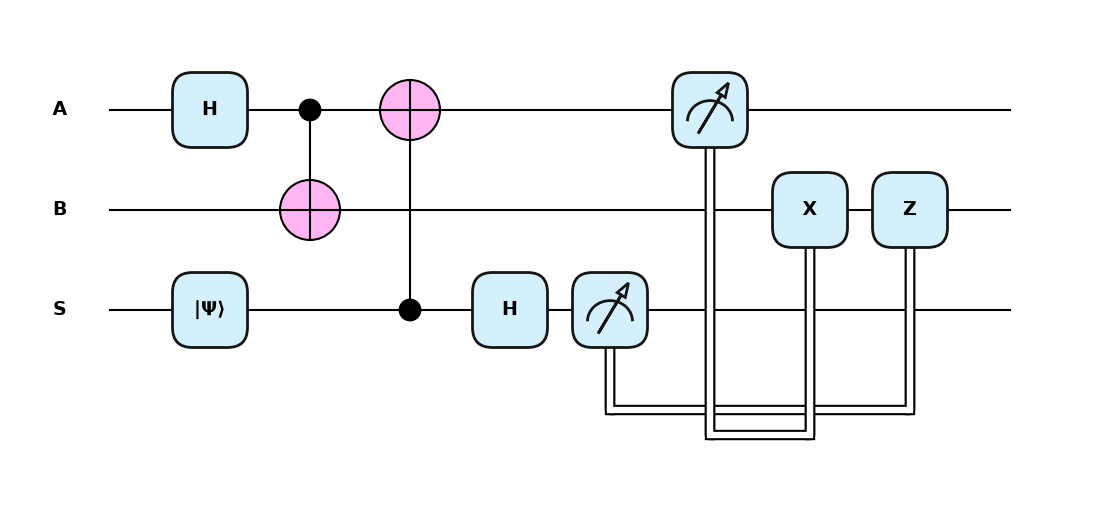

In [4]:
state = np.array([1 / np.sqrt(2) + 0.3j, 0.4 - 0.5j])
_ = qp.draw_mpl(teleport, style="pennylane")(state)